Processing RN-50
Processing RN-50 Salman
Processing ViT-S Singh
Processing ConvNeXt Liu
Processing Swin Liu


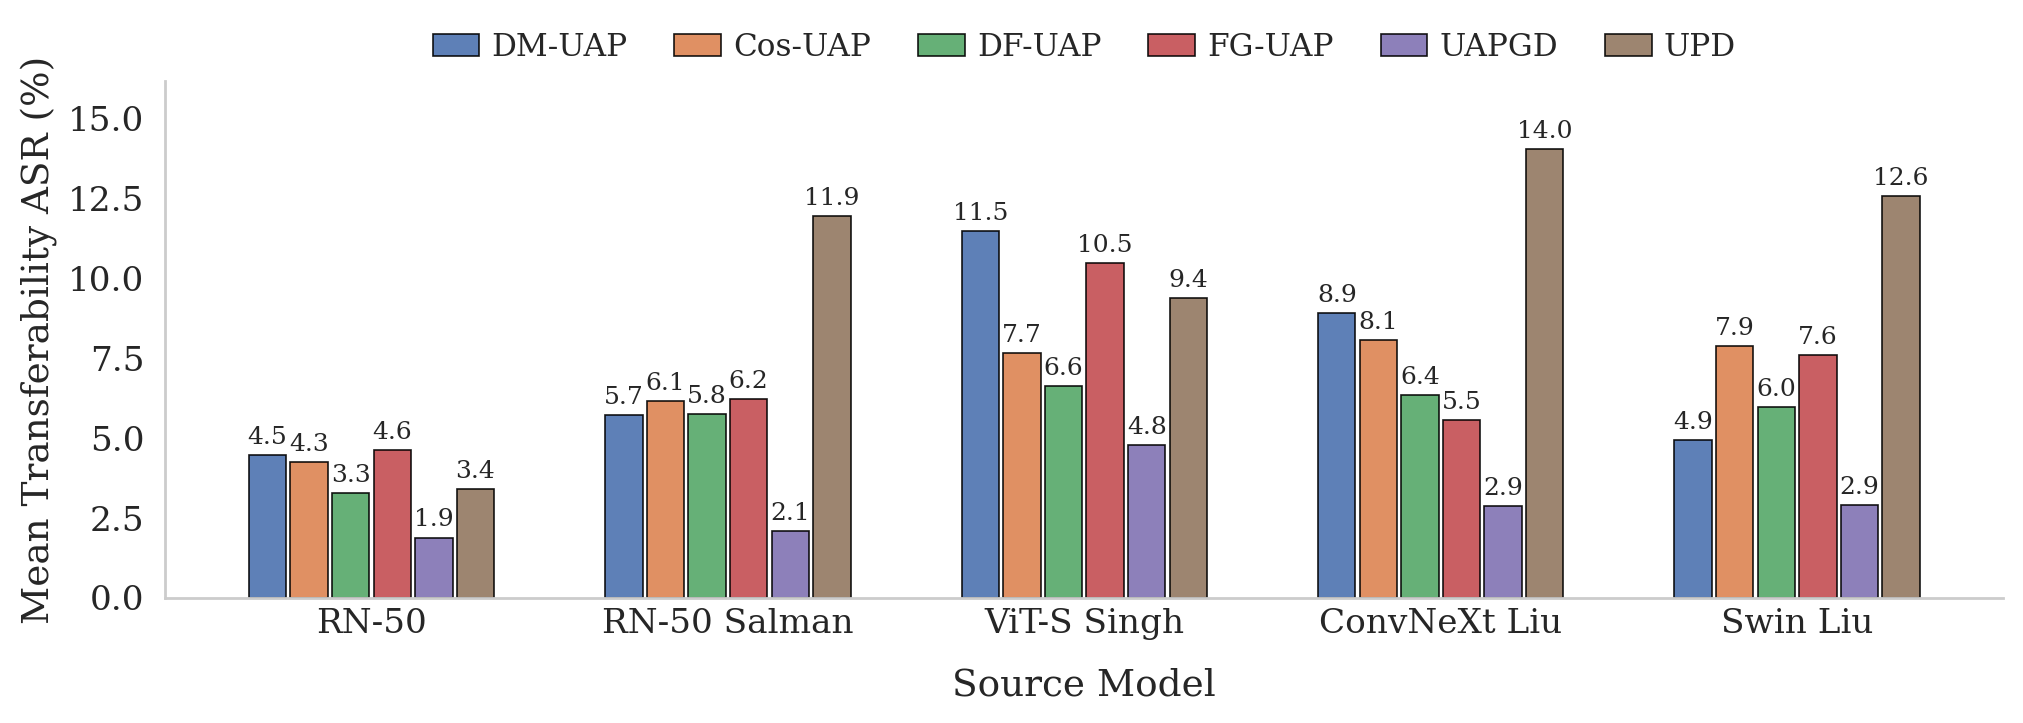

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------
# Style Configuration (Paper Quality)
# -----------------------------
sns.set_context("paper", font_scale=1.4)
sns.set_style("whitegrid", {"grid.linestyle": ":", "grid.linewidth": 0.8})
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif", "serif"],
    "axes.titleweight": "bold",
    "axes.labelweight": "medium",
    "figure.dpi": 200,
})

# -----------------------------
# Data (ROBUST SOURCES ONLY)
# -----------------------------
targets = ["RN-50 Salman", "ViT-S Singh", "ConvNeXt Liu", "Swin Liu", "RN50 Wong", "WRN-50 Peng"]
attacks = ["DM-UAP", "Cos-UAP", "DF-UAP", "FG-UAP", "UAPGD", "UPD"]

data = {
    "RN-50": {
        "DM-UAP":  [7.52, 3.38, 1.95, 1.64, 6.35, 5.96],
        "Cos-UAP": [7.27, 3.05, 1.73, 1.70, 6.06, 5.70],
        "DF-UAP":  [5.79, 2.59, 1.45, 1.29, 4.86, 3.68],
        "FG-UAP":  [7.95, 3.16, 2.15, 1.65, 6.78, 5.96],
        "UAPGD":   [3.59, 1.26, 0.96, 0.60, 3.16, 1.70],
        "UPD":     [6.09, 2.70, 1.31, 1.35, 4.95, 3.90],
    },
    "RN-50 Salman": {
        "DM-UAP":  [15.02, 3.99, 2.90, 2.42, 10.26, 8.98],
        "Cos-UAP": [12.07, 3.24, 2.67, 2.33, 16.34, 6.16],
        "DF-UAP":  [11.89, 4.81, 2.76, 2.81, 10.73, 7.68],
        "FG-UAP":  [10.88, 3.60, 2.63, 2.77, 16.05, 5.97],
        "UAPGD":   [14.56, 1.74, 0.99, 1.22,  3.45, 2.98],
        "UPD":     [23.73, 8.18, 6.76, 6.72, 18.11, 19.93],
    },
    "ViT-S Singh": {
        "DM-UAP":  [17.23, 9.44, 6.12, 5.62, 13.82, 14.65],
        "Cos-UAP": [12.23, 4.68, 3.23, 2.96, 10.80, 9.10],
        "DF-UAP":  [10.48, 4.81, 2.81, 2.89,  9.46, 7.41],
        "FG-UAP":  [16.28, 6.98, 4.60, 4.80, 14.00, 12.64],
        "UAPGD":   [ 7.39, 3.67, 2.07, 1.95,  7.03, 5.43],
        "UPD":     [11.96,10.84, 6.23, 5.48, 10.82, 12.37],
    },
    "ConvNeXt Liu": {
        "DM-UAP":  [14.59, 5.47, 4.64, 3.74, 10.02, 10.72],
        "Cos-UAP": [11.45, 3.50, 2.76, 3.02, 16.32, 6.02],
        "DF-UAP":  [ 9.52, 4.24, 2.61, 2.34,  8.72, 6.95],
        "FG-UAP":  [ 8.34, 3.23, 2.69, 2.36,  8.48, 5.32],
        "UAPGD":   [ 4.13, 2.31, 1.92, 0.90,  4.36, 2.57],
        "UPD":     [20.38, 7.82, 6.83, 6.39, 16.93, 18.72],
    },
    "Swin Liu": {
        "DM-UAP":  [7.79, 2.85, 2.21, 1.87, 6.33, 5.48],
        "Cos-UAP": [11.29, 3.41, 2.71, 2.93, 16.08, 5.85],
        "DF-UAP":  [ 8.87, 3.82, 2.26, 2.31,  8.23, 6.66],
        "FG-UAP":  [10.40, 3.43, 2.51, 2.91, 15.61, 6.08],
        "UAPGD":   [ 4.35, 1.87, 1.34, 1.27,  4.28, 2.59],
        "UPD":     [18.29, 6.69, 5.93, 6.49, 15.25, 16.75],
    },
}

# -----------------------------
# Data Processing
# -----------------------------
def get_values_excluding_diag(source: str, attack: str) -> np.ndarray:
    vals = np.array(data[source][attack], dtype=float)
    if source in targets:
        idx = targets.index(source)
        vals = np.delete(vals, idx)
    return vals

def build_aggregated_df(sources):
    rows = []
    for s in sources:
        print(f"Processing {s}")
        for a in attacks:
            vals = get_values_excluding_diag(s, a)
            rows.append({
                "source": s,
                "attack": a,
                "mean_asr": vals.mean(),
                "std_asr": vals.std(ddof=1)
            })
    return pd.DataFrame(rows)

sources = list(data.keys())
df = build_aggregated_df(sources)

source_order = list(data.keys())
df["source"] = pd.Categorical(df["source"], categories=source_order, ordered=True)
df["attack"] = pd.Categorical(df["attack"], categories=attacks, ordered=True)
df = df.sort_values(["source", "attack"]).reset_index(drop=True)

# -----------------------------
# Plotting
# -----------------------------
colors = sns.color_palette("deep", n_colors=len(attacks))

fig, ax = plt.subplots(figsize=(10, 3.5), constrained_layout=True)

x = np.arange(len(source_order))
n_bars = len(attacks)

total_width = 0.70
bar_w = total_width / n_bars
offsets = (np.arange(n_bars) - (n_bars - 1) / 2) * bar_w

max_y = 0.0

for j, a in enumerate(attacks):
    subset = df[df["attack"] == a]
    
    y_vals = []
    y_errs = []
    for s in source_order:
        row = subset[subset["source"] == s].iloc[0]
        y_vals.append(row["mean_asr"])
        y_errs.append(row["std_asr"])
    
    current_max = max(np.array(y_vals))
    max_y = max(max_y, current_max)
    
    rects = ax.bar(
        x + offsets[j],
        y_vals,
        width=bar_w * 0.9,     # Add a tiny gap between intra-group bars
        label=a,
        # yerr=y_errs,
        color=colors[j],
        edgecolor="black",
        linewidth=0.6,
        capsize=2,
        alpha=0.9,
        # error_kw={'elinewidth': 1.2, 'markeredgewidth': 0.0, 'ecolor': 'black'}
    )
    
    # Add scalar values for each bar
    for rect in rects:
        height = rect.get_height()
        ax.text(
            rect.get_x() + rect.get_width() / 2., 
            height + 0.2, 
            "{:.1f}".format(height),
            ha='center', 
            va='bottom', 
            fontsize=9, 
            # fontweight='bold',
            rotation=0
        )

ax.set_xticks(x)
ax.set_xticklabels(source_order, rotation=0, ha="center")
ax.set_ylabel("Mean Transferability ASR (%)")
ax.set_xlabel("Source Model", labelpad=10)

ax.set_ylim(0, max_y * 1.15)

sns.despine(ax=ax, trim=False)
ax.tick_params(axis='y', length=4)
ax.tick_params(axis='x', length=0)
ax.grid(False)

ax.legend(
    ncol=len(attacks),
    loc="upper center",
    bbox_to_anchor=(0.5, 1.15),
    frameon=False,
    columnspacing=1.5,
    handletextpad=0.4,
    handlelength=1.5,
    fontsize="small"
)

fig.savefig("robust_transfer_final.pdf", format='pdf', bbox_inches='tight', dpi=600)
plt.show()

In [25]:
# plot for num steps -> ASR
data = {
    "RN-50": {
        1: [0.96582, 0.9641],
        2: [0.96926, 0.96582],
        4: [0.95747, 0.96264],
        8: [0.96078, 0.95787],
        16: [0.96701, 0.96489],
        32: [0.96251],
        64: [0.96449],
    },
    "RN-50 Salman": {
        1: [0.21023, 0.1749],
        2: [0.21261, 0.19312],
        4: [0.17538, 0.15985],
        8: [0.17189, 0.18821],
        16: [0.20722, 0.20516],
        32: [0.20247, 0.17538],
        64: [0.16318, 0.21324],
    },
    "ViT-S Singh": {
        1: [0.10691, 0.10344],
        2: [0.10483, 0.10011],
        4: [0.10996, 0.095951],
        8: [0.1033, 0.1058],
        16: [0.10455, 0.073489],
        32: [0.098863, 0.091514],
        64: [0.074737, 0.1033],
    },
}

for k, v in data.items():
    for k2, v2 in v.items():
        data[k][k2] = [x * 100 for x in v2]

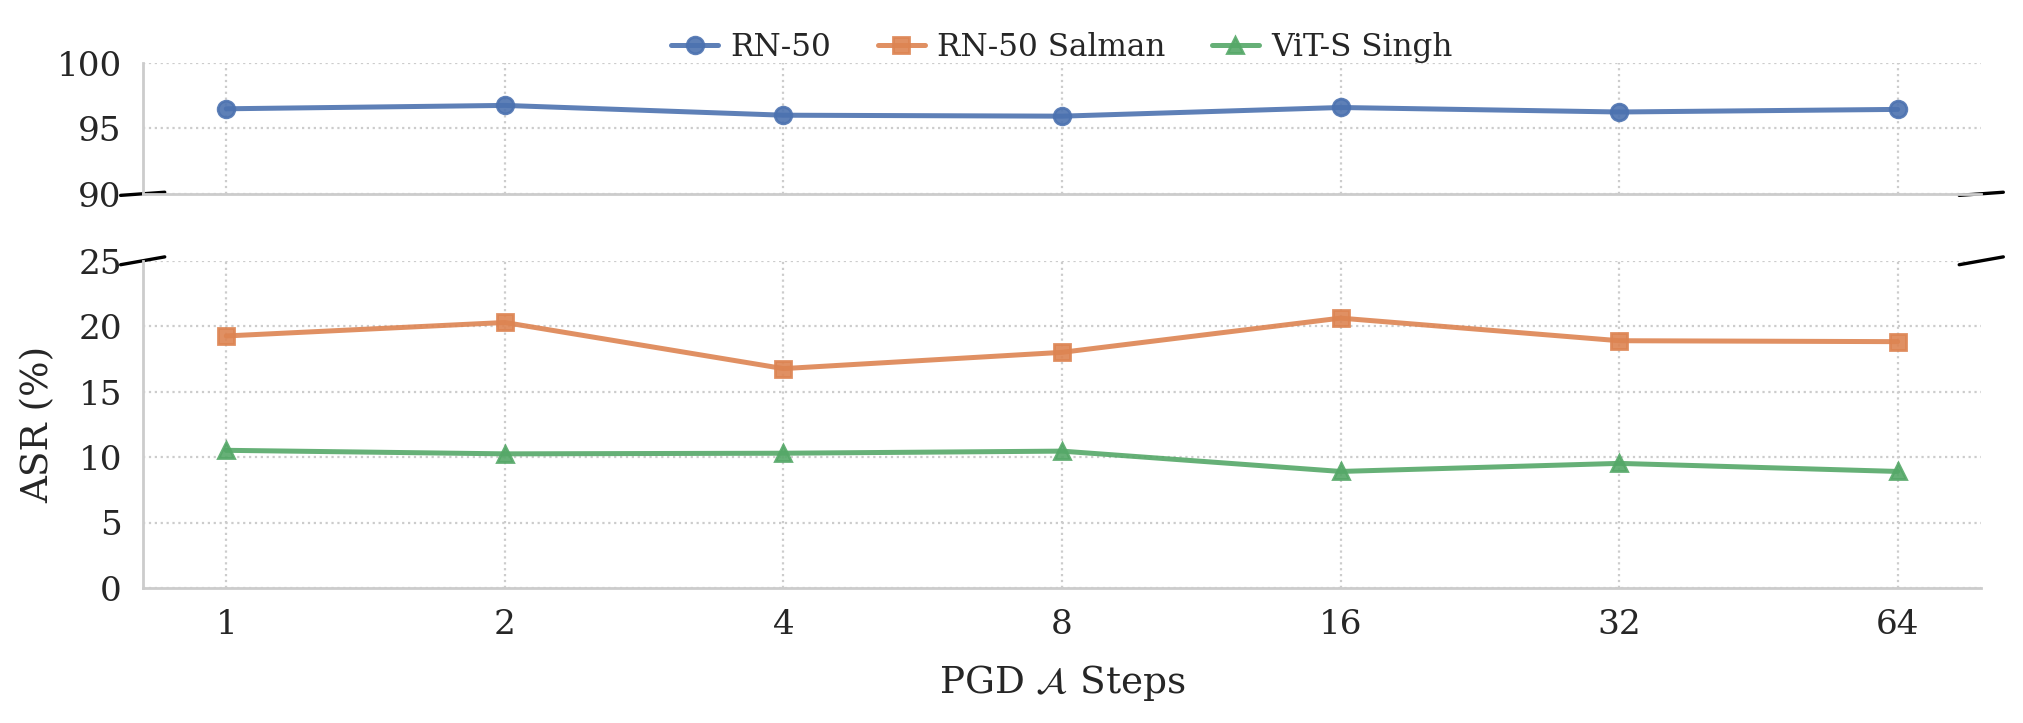

In [32]:
fig, (ax_top, ax_bot) = plt.subplots(
    2, 1,
    figsize=(10, 3.5),
    sharex=True,
    gridspec_kw={"height_ratios": [1, 2.5], "hspace": 0.1},
    constrained_layout=True
)

markers = ['o', 's', '^', 'D', 'v', '<', '>']
colors = sns.color_palette("deep", n_colors=len(data))

for idx, (model, values_dict) in enumerate(data.items()):
    keys = sorted([k for k in values_dict.keys() if values_dict[k]])
    means = [np.mean(values_dict[k]) for k in keys]

    for ax in (ax_top, ax_bot):
        ax.plot(
            keys,
            means,
            marker=markers[idx % len(markers)],
            label=model,
            linewidth=1.8,
            markersize=6,
            color=colors[idx % len(colors)],
            alpha=0.9
        )

# X axis: keep log scale
for ax in (ax_top, ax_bot):
    ax.set_xscale("log", base=2)
    ax.set_xticks([1, 2, 4, 8, 16, 32, 64])
    ax.set_xticklabels([1, 2, 4, 8, 16, 32, 64])
    ax.tick_params(axis='both', length=4)

# Y axis: linear, split into two ranges
ax_bot.set_ylim(0, 25)
ax_top.set_ylim(90, 100)

ax_bot.set_yticks([0, 5, 10, 15, 20, 25])
ax_top.set_yticks([90, 95, 100])

ax_bot.set_xlabel(r"PGD $\mathcal{A}$ Steps", labelpad=8)
ax_bot.set_ylabel("ASR (%)", labelpad=8)

# Remove touching spines
ax_top.spines["bottom"].set_visible(False)
ax_bot.spines["top"].set_visible(False)

ax_top.tick_params(labelbottom=False)

# Add diagonal break marks
d = 0.012
kwargs = dict(transform=ax_top.transAxes, color="k", clip_on=False, linewidth=1.2)
ax_top.plot((-d, +d), (-d, +d), **kwargs)
ax_top.plot((1 - d, 1 + d), (-d, +d), **kwargs)

kwargs = dict(transform=ax_bot.transAxes, color="k", clip_on=False, linewidth=1.2)
ax_bot.plot((-d, +d), (1 - d, 1 + d), **kwargs)
ax_bot.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)

# Legend only once
# ax_top.legend(frameon=True, framealpha=0.9, loc="right", handlelength=1.5)

ax_top.legend(
    ncol=len(attacks),
    loc="upper center",
    bbox_to_anchor=(0.5, 1.45),
    frameon=False,
    columnspacing=1.5,
    handletextpad=0.4,
    handlelength=1.5,
    fontsize="small"
)

sns.despine(ax=ax_top, trim=False)
sns.despine(ax=ax_bot, trim=False)

fig.savefig("pgd_steps_plot.pdf", format='pdf', bbox_inches='tight', dpi=600)

plt.show()

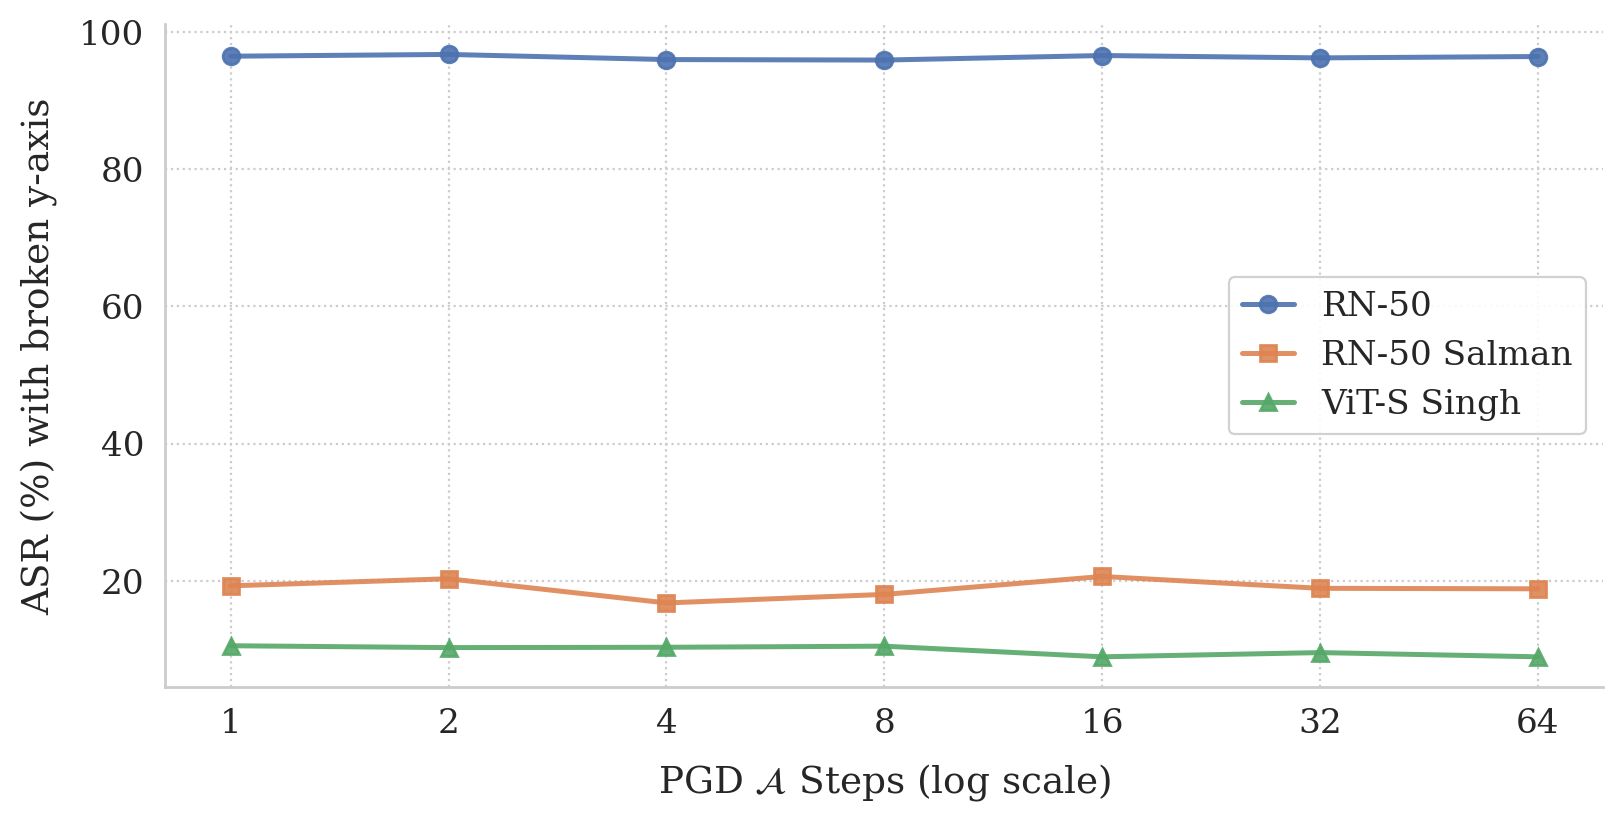

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------
# Style Configuration (Paper Quality)
# Same as above for consistency
# -----------------------------
sns.set_context("paper", font_scale=1.4)
sns.set_style("whitegrid", {"grid.linestyle": ":", "grid.linewidth": 0.8})
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif", "serif"],
    "axes.titleweight": "bold",
    "axes.labelweight": "medium",
    "figure.dpi": 200,
})

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)

# Markers for distinction + color palette
markers = ['o', 's', '^', 'D', 'v', '<', '>']
colors = sns.color_palette("deep", n_colors=len(data)) 

idx = 0
for model, values_dict in data.items():
    keys = sorted([k for k in values_dict.keys() if values_dict[k]])
    means = [np.mean(values_dict[k]) for k in keys]
    
    label_str = model
    
    ax.plot(
        keys, 
        means, 
        marker=markers[idx % len(markers)], 
        label=label_str, 
        linewidth=1.8,
        markersize=6,
        color=colors[idx % len(colors)],
        alpha=0.9
    )
    idx += 1

ax.set_xlabel(r"PGD $\mathcal{A}$ Steps (log scale)", labelpad=8)
ax.set_ylabel("ASR (%) with broken y-axis", labelpad=8)

# Legend adjustment
ax.legend(frameon=True, framealpha=0.9, loc='best', handlelength=1.5)

ax.set_xscale('log', base=2)
# ax.set_yscale('log', base=10)

# Specific ticks for powers of 2 (if that's what the data is)
ax.set_xticks([1, 2, 4, 8, 16, 32, 64])
ax.set_xticklabels([1, 2, 4, 8, 16, 32, 64])


# Remove top/right spines
sns.despine(ax=ax, trim=False)
ax.tick_params(axis='both', length=4)

plt.show()